# Chương 3 — Ứng dụng 1: Phân tích Giỏ hàng (Market Basket Analysis)

**Thuật toán sử dụng:** **Optimized CHARM** (`CharmMining.jl`, tự cài đặt từ đầu bằng Julia — Chương 1) kết hợp bộ sinh luật kết hợp dựa trên **bao đóng Galois (`ClosureSupportIndex`)** (`src/rules.jl`).

**Tập dữ liệu:** [UCI Online Retail](https://archive.ics.uci.edu/dataset/352/online+retail) (giao dịch bán lẻ trực tuyến tại Vương quốc Anh, 12/2010 – 12/2011, 541.909 dòng hóa đơn).

### Tại sao cách biến đổi dữ liệu này phù hợp với thuật toán CHARM?
- Mỗi hóa đơn (`InvoiceNo`) sau khi loại bỏ đơn hủy, số lượng/giá âm và các mã phí dịch vụ (`POST`, `DOT`, `M`, ...) được gom thành một giao dịch (giỏ hàng) gồm tập các mã sản phẩm (`StockCode`) duy nhất.
- Dữ liệu bán lẻ trực tuyến có đặc tính **rất thưa (sparse)** (~4.000 SKU, mật độ ma trận < 0.6%), nhưng chứa nhiều **bộ sản phẩm đi kèm chặt chẽ** (ví dụ: bộ tách trà nhiều màu, bộ hộp cơm, bộ túi xách cùng họa tiết). Các bộ này tạo ra lượng lớn tập con có **cùng độ hỗ trợ (support)**.
- Thuật toán **CHARM** chỉ khai thác các **tập phổ biến đóng (Closed Frequent Itemsets)**, loại bỏ hoàn toàn các tập con dư thừa ngay trong quá trình duyệt cây IT-Tree mà vẫn **bảo toàn 100% thông tin support** để sinh chính xác mọi luật kết hợp (Support, Confidence, Lift).

## 1. Thiết lập môi trường (Google Colab / Local)
Ô dưới đây tự động cài đặt Julia (nếu đang chạy trên Google Colab chưa có sẵn Julia) và xác định thư mục gốc của repository.

In [1]:
import os, shutil, subprocess
from pathlib import Path

# Cài đặt Julia trên Google Colab nếu chưa có
if shutil.which("julia") is None:
    print("Installing Julia 1.11.4 for Google Colab...")
    subprocess.run(
        "curl -fsSL https://julialang-s3.julialang.org/bin/linux/x64/1.11/julia-1.11.4-linux-x86_64.tar.gz -o julia.tar.gz "
        "&& tar -xzf julia.tar.gz -C /usr --strip-components 1",
        shell=True, check=True,
    )

print(subprocess.check_output(["julia", "--version"], text=True).strip())

# Đảm bảo thư mục làm việc là repo root
cwd = Path.cwd()
if (cwd / "src" / "CharmMining.jl").exists():
    REPO_ROOT = cwd
elif (cwd.parent / "src" / "CharmMining.jl").exists():
    REPO_ROOT = cwd.parent
    os.chdir(REPO_ROOT)
else:
    raise FileNotFoundError(
        "Không tìm thấy src/CharmMining.jl. Trên Google Colab, hãy git clone repo trước rồi cd vào thư mục repo."
    )

print("Working directory:", REPO_ROOT)

julia version 1.13.3
Working directory: C:\Users\maduc\frequent-itemset-mining


## 2. Tải, làm sạch và chuyển đổi dữ liệu sang định dạng SPMF
Script `applications/market_basket/prepare_data.py` thực hiện:
1. Tải bộ dữ liệu **UCI Online Retail** (nếu chưa có sẵn cục bộ).
2. Loại bỏ bản ghi thiếu `InvoiceNo`/`StockCode`/`Description`, đơn hủy (`InvoiceNo` bắt đầu bằng `'C'`), `Quantity <= 0`, `UnitPrice <= 0`, và các mã phí dịch vụ không phải hàng hóa (`POST`, `DOT`, `M`, `BANK CHARGES`, ...).
3. Chuẩn hóa tên sản phẩm theo `StockCode`, gán `item_id` nguyên liên tục `1..M` tất định.
4. Gom theo `InvoiceNo` và xuất `data/applications/online_retail/transactions.txt` (chuẩn SPMF) cùng từ điển `item_mapping.csv`.

In [2]:
import json
import pandas as pd

subprocess.run(["python", "applications/market_basket/prepare_data.py"], check=True)

with open("results/app1/dataset_summary.json", encoding="utf-8") as f:
    summary = json.load(f)

summary_rows = [
    ("Số dòng hóa đơn gốc (Raw rows)", f"{summary['raw_rows']:,}"),
    ("Loại bỏ thiếu InvoiceNo/StockCode/Description", f"{summary['dropped_missing_fields']:,}"),
    ("Loại bỏ đơn hàng bị hủy (InvoiceNo bắt đầu bằng 'C')", f"{summary['dropped_canceled_invoices']:,}"),
    ("Loại bỏ Quantity <= 0 hoặc UnitPrice <= 0", f"{summary['dropped_non_positive_qty_or_price']:,}"),
    ("Loại bỏ mã phí dịch vụ / không phải hàng hóa", f"{summary['dropped_non_product_items']:,}"),
    ("Số dòng sạch còn lại (Clean rows)", f"{summary['clean_rows']:,}"),
    ("Số giao dịch / hóa đơn (|D|)", f"{summary['n_transactions']:,}"),
    ("Số giao dịch có >= 2 sản phẩm", f"{summary['n_multi_item_transactions']:,}"),
    ("Số sản phẩm duy nhất (|I|)", f"{summary['n_unique_items']:,}"),
    ("Kích thước giỏ hàng (TB / Trung vị / Tối đa)", f"{summary['avg_basket_size']} / {summary['median_basket_size']} / {summary['max_basket_size']}"),
    ("Mật độ ma trận giao dịch", f"{summary['matrix_density'] * 100:.3f}%"),
]
display(pd.DataFrame(summary_rows, columns=["Chỉ số", "Giá trị"]))

,Chỉ số,Giá trị
0,Số dòng hóa đơn gốc (Raw rows),"541,909"
1,Loại bỏ thiếu InvoiceNo/StockCode/Description,"1,454"
2,Loại bỏ đơn hàng bị hủy (InvoiceNo bắt đầu bằn...,"9,288"
3,Loại bỏ Quantity <= 0 hoặc UnitPrice <= 0,"1,063"
4,Loại bỏ mã phí dịch vụ / không phải hàng hóa,"2,536"
5,Số dòng sạch còn lại (Clean rows),"527,568"
6,Số giao dịch / hóa đơn (|D|),"19,773"
7,Số giao dịch có >= 2 sản phẩm,"18,267"
8,Số sản phẩm duy nhất (|I|),"3,787"
9,Kích thước giỏ hàng (TB / Trung vị / Tối đa),26.15 / 15 / 1105


## 3. Khai thác Tập phổ biến đóng & Sinh Luật kết hợp bằng `CharmMining.jl`
Toàn bộ kết quả được tạo trực tiếp bởi cài đặt **Optimized CHARM (`mine_file_bit`)** và module sinh luật kết hợp theo bao đóng (`generate_rules`, `top_rules_by_lift`) trong `src/rules.jl` — **không sử dụng bất kỳ thư viện FIM bên ngoài nào**.

In [3]:
subprocess.run(["julia", "--project=.", "applications/market_basket/run_mba.jl"], check=True)

CompletedProcess(args=['julia', '--project=.', 'applications/market_basket/run_mba.jl'], returncode=0)

## 4. Phân tích kết quả: Độ nhạy theo `minsup` & Top-10 Luật kết hợp theo Lift

In [4]:
sens_df = pd.read_csv("results/app1/minsup_sensitivity.csv")
print("=== Bảng độ nhạy theo ngưỡng minsup ===")
display(sens_df)

top10_df = pd.read_csv("results/app1/top10_rules_lift_dedup.csv")
print("\n=== Top-10 Luật kết hợp theo Lift (minsup = 1.0%, minconf = 50%, đã khử cặp đối xứng) ===")
display(top10_df[["rank", "antecedent_names", "consequent_names", "support_count", "support_pct", "confidence_pct", "lift", "leverage"]])

=== Bảng độ nhạy theo ngưỡng minsup ===


,minsup_pct,minsup_count,num_closed_itemsets,num_closed_len2plus,max_itemset_len,num_rules_conf50,runtime_ms
0,5.0,989,36,0,1,0,0.149
1,3.0,594,143,10,2,14,1.585
2,2.5,495,234,43,3,40,3.028
3,2.0,396,395,93,3,61,10.641
4,1.5,297,763,282,4,215,23.737
5,1.0,198,2026,1197,5,962,71.261
6,0.8,159,3804,2772,5,2882,114.822



=== Top-10 Luật kết hợp theo Lift (minsup = 1.0%, minconf = 50%, đã khử cặp đối xứng) ===


,rank,antecedent_names,consequent_names,support_count,support_pct,confidence_pct,lift,leverage
0,1,HERB MARKER THYME,HERB MARKER ROSEMARY + HERB MARKER PARSLEY,203,1.0267,85.65,78.7738,0.010136
1,2,HERB MARKER THYME + HERB MARKER PARSLEY,HERB MARKER ROSEMARY,203,1.0267,95.31,78.5195,0.010136
2,3,HERB MARKER ROSEMARY,HERB MARKER THYME + HERB MARKER BASIL,200,1.0115,83.33,78.4643,0.009986
3,4,HERB MARKER ROSEMARY + HERB MARKER BASIL,HERB MARKER THYME,200,1.0115,93.46,77.9723,0.009985
4,5,HERB MARKER THYME,HERB MARKER ROSEMARY,221,1.1177,93.25,76.8255,0.011031
5,6,HERB MARKER THYME + HERB MARKER ROSEMARY,HERB MARKER PARSLEY,203,1.0267,91.86,76.3131,0.010132
6,7,HERB MARKER THYME,HERB MARKER PARSLEY,213,1.0772,89.87,74.6667,0.010628
7,8,HERB MARKER PARSLEY,HERB MARKER ROSEMARY,215,1.0873,90.34,74.4257,0.010727
8,9,HERB MARKER THYME + HERB MARKER ROSEMARY,HERB MARKER BASIL,200,1.0115,90.50,73.9426,0.009978
9,10,HERB MARKER PARSLEY,HERB MARKER MINT,212,1.0722,89.08,73.3872,0.010576


## 5. Trực quan hóa kết quả

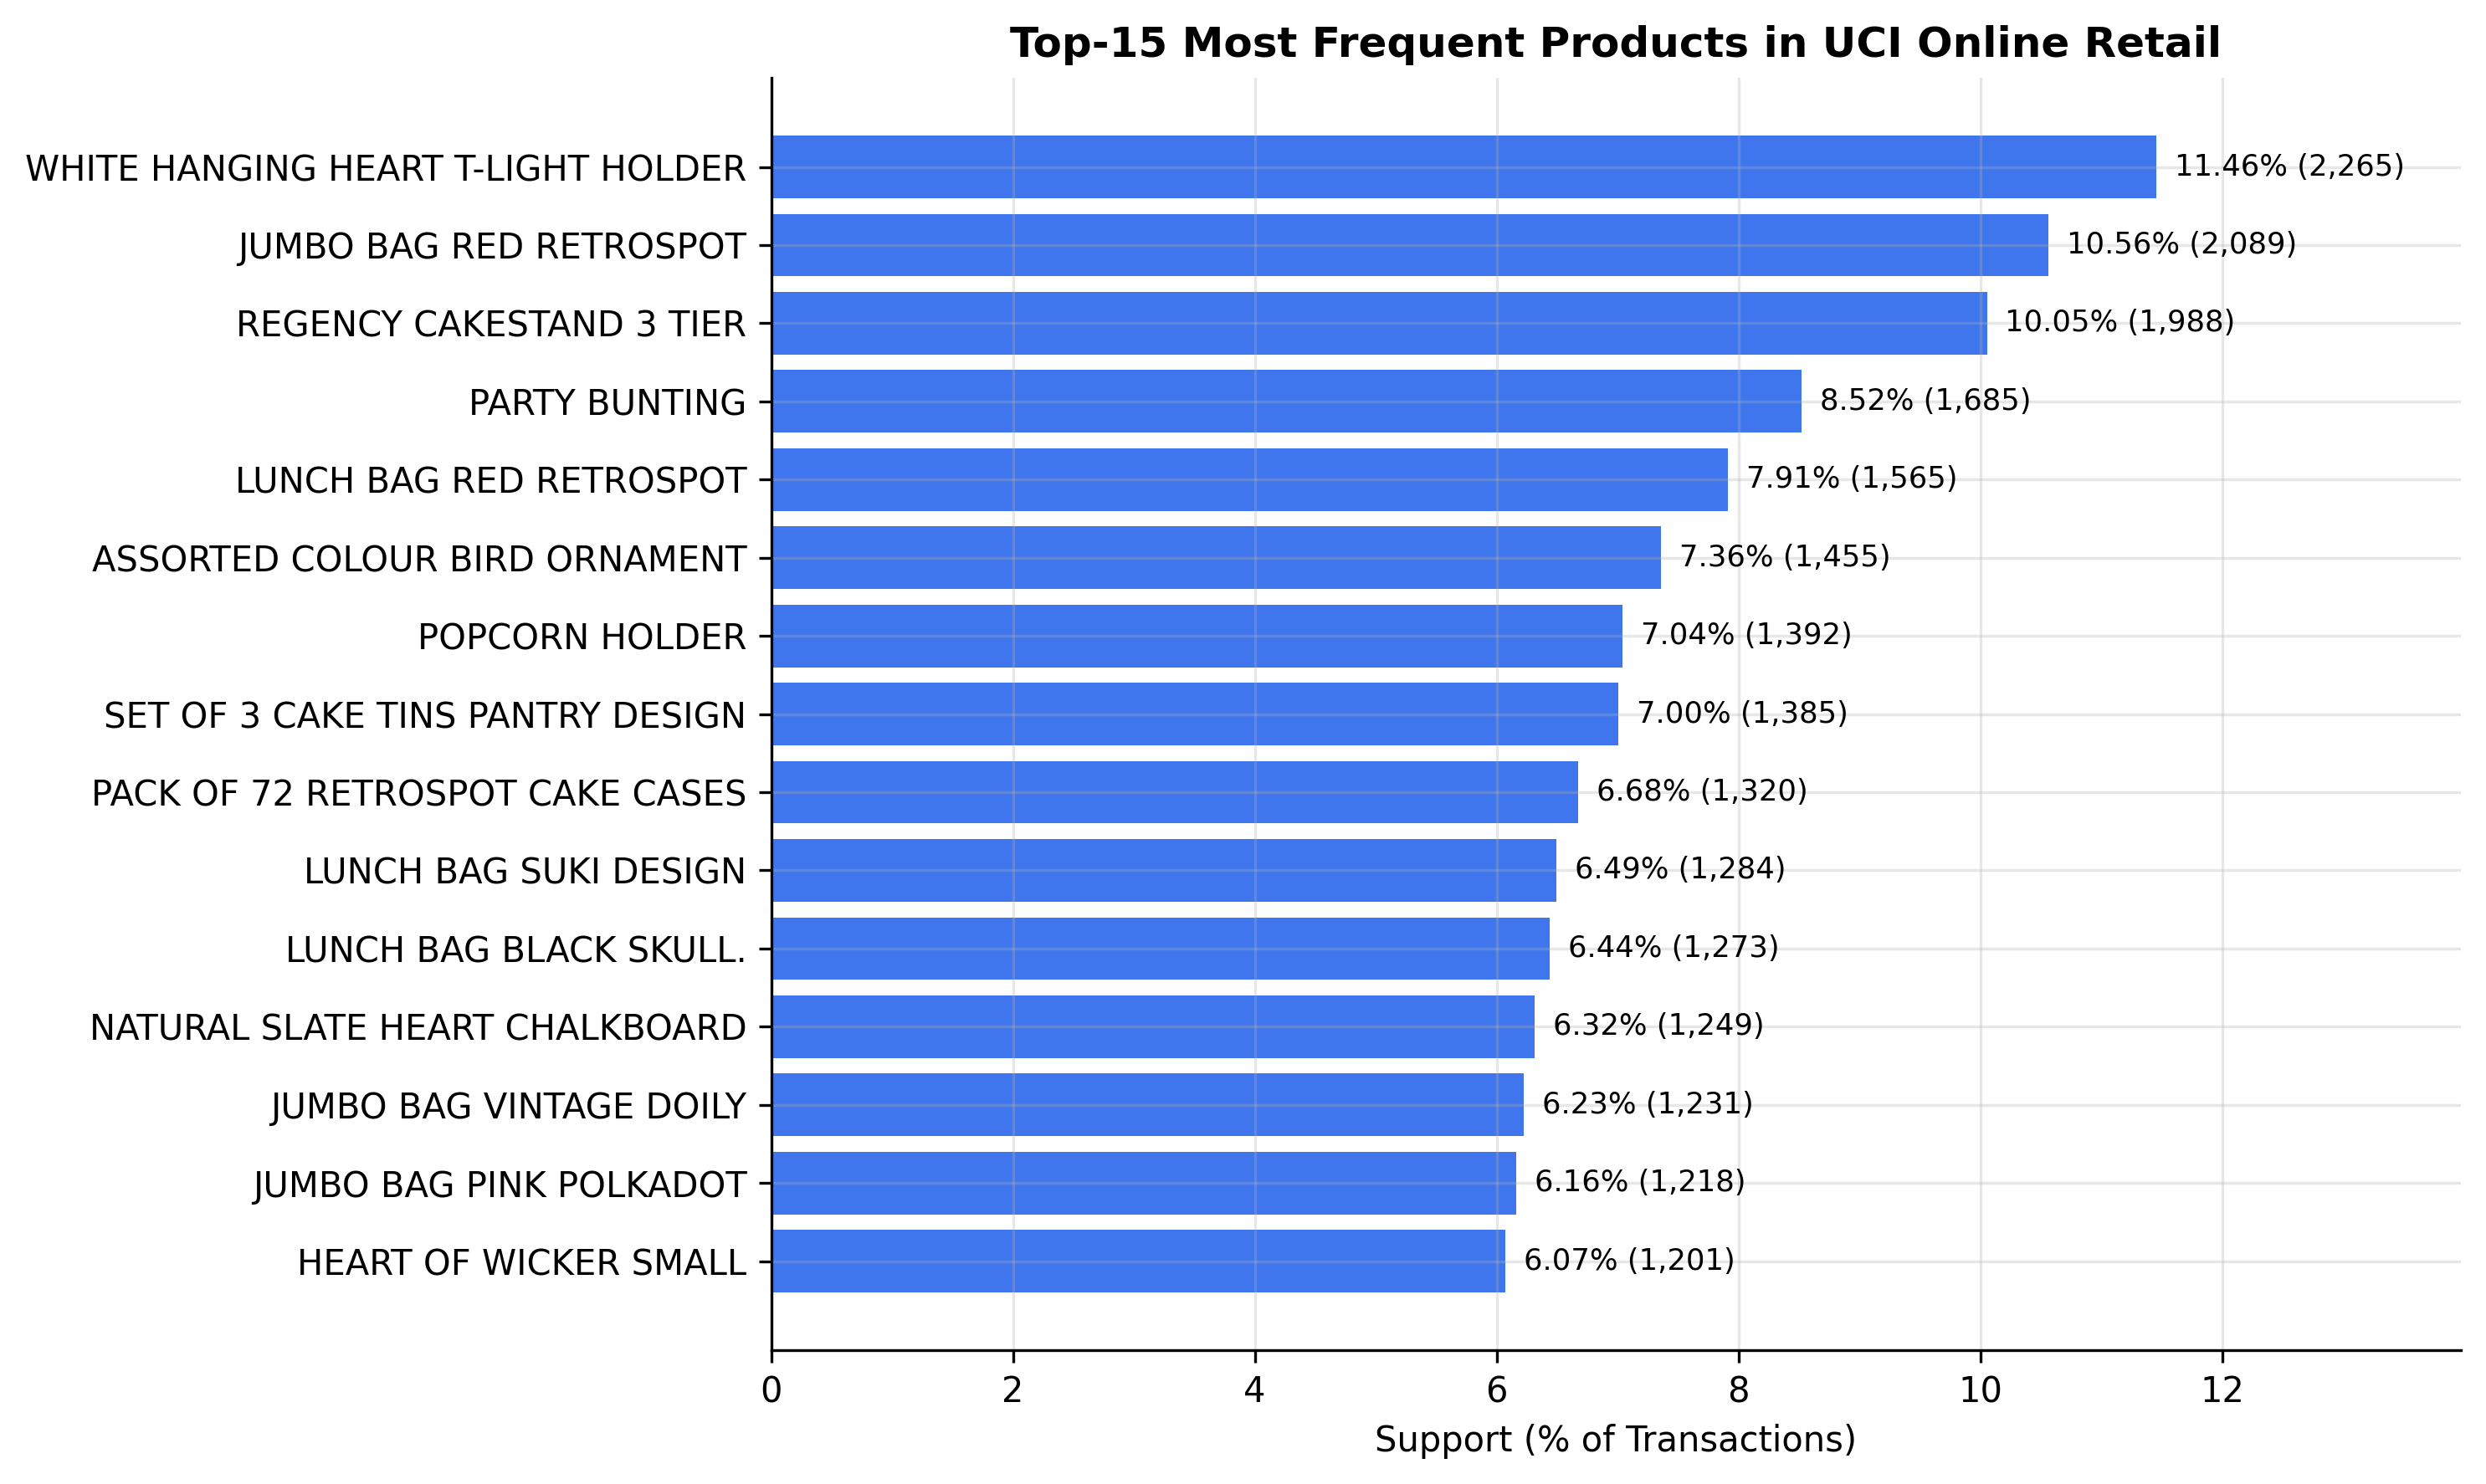

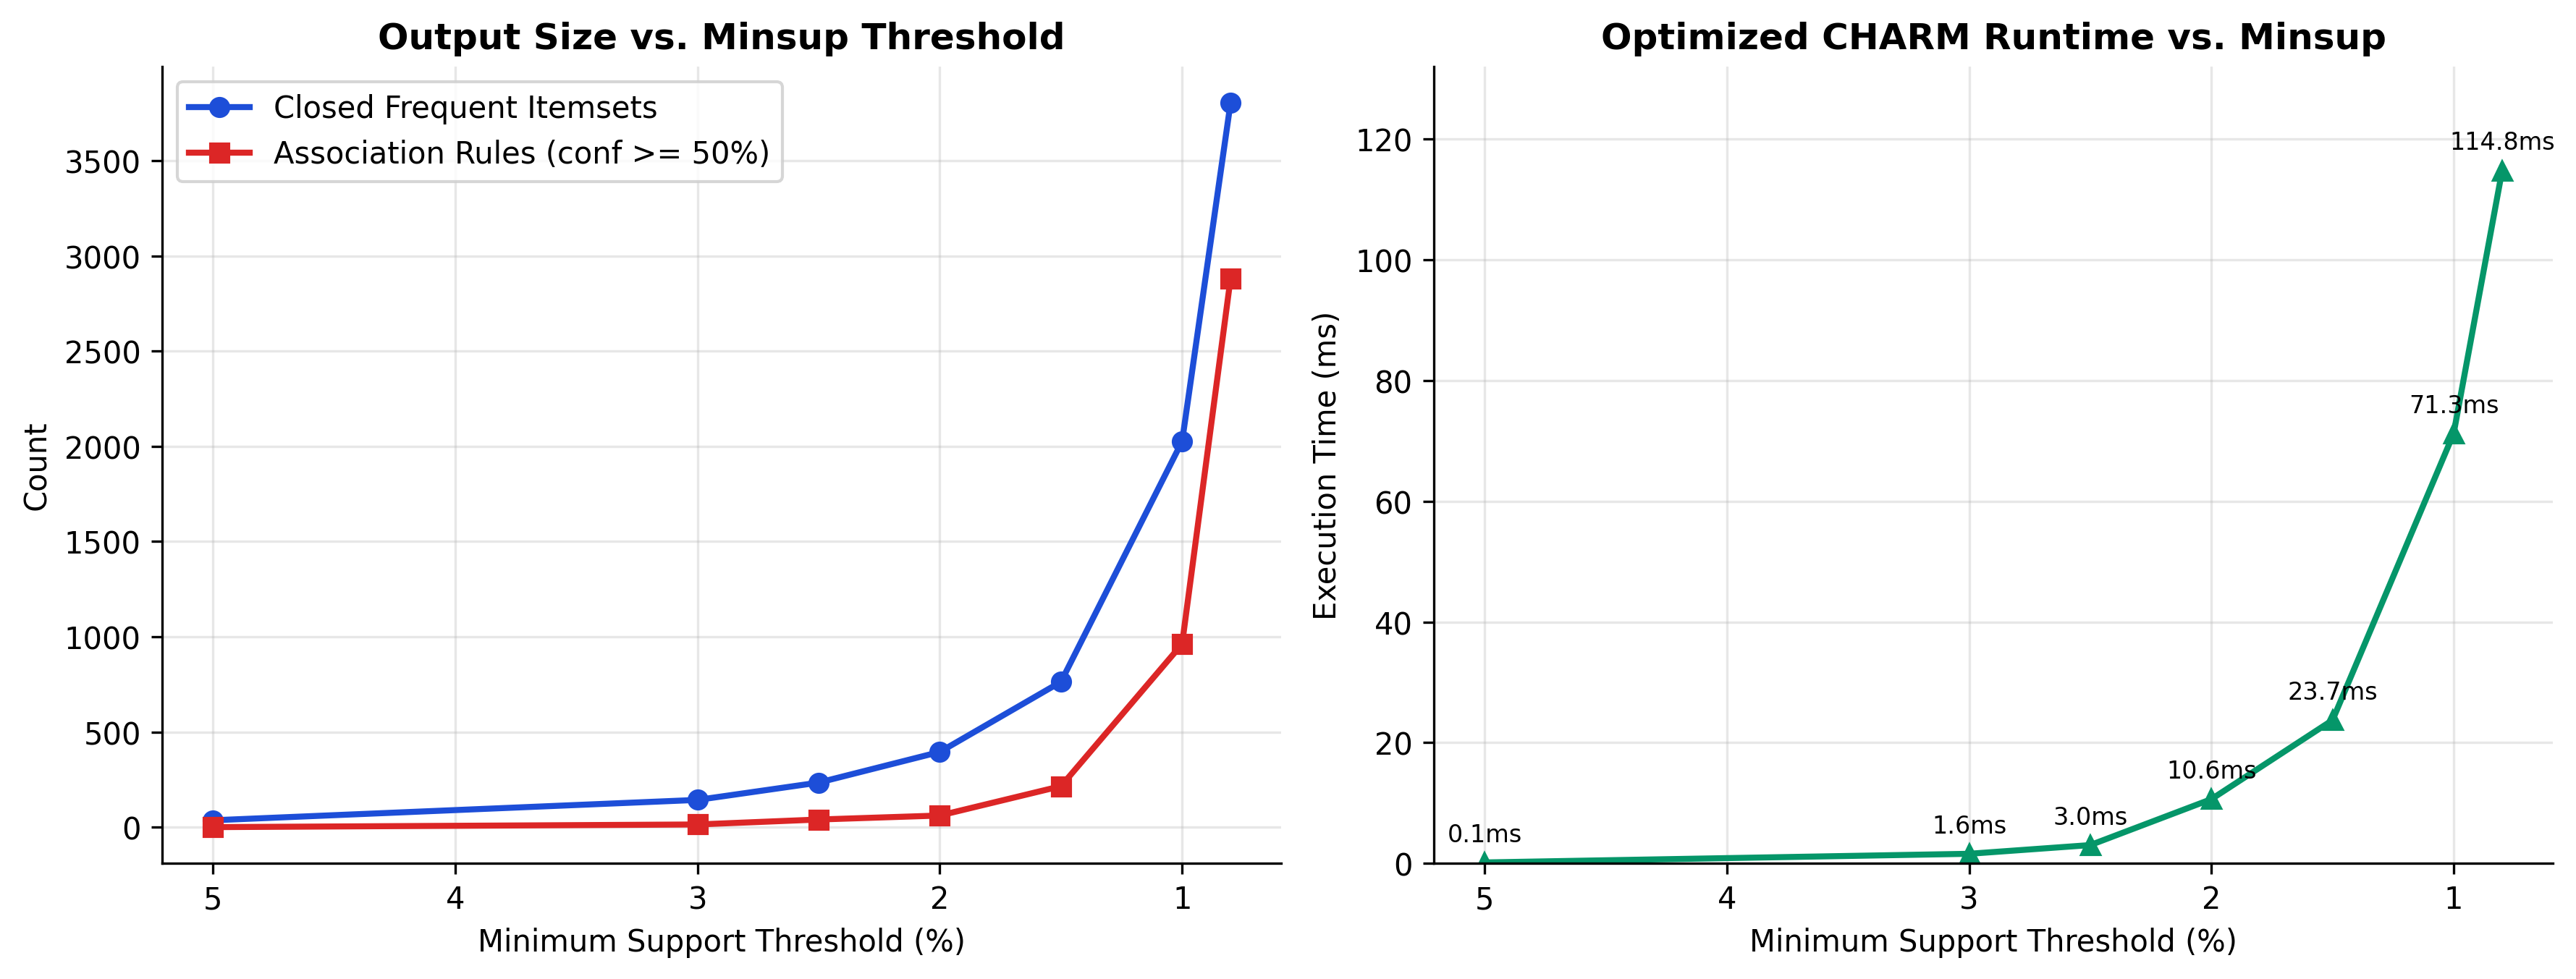

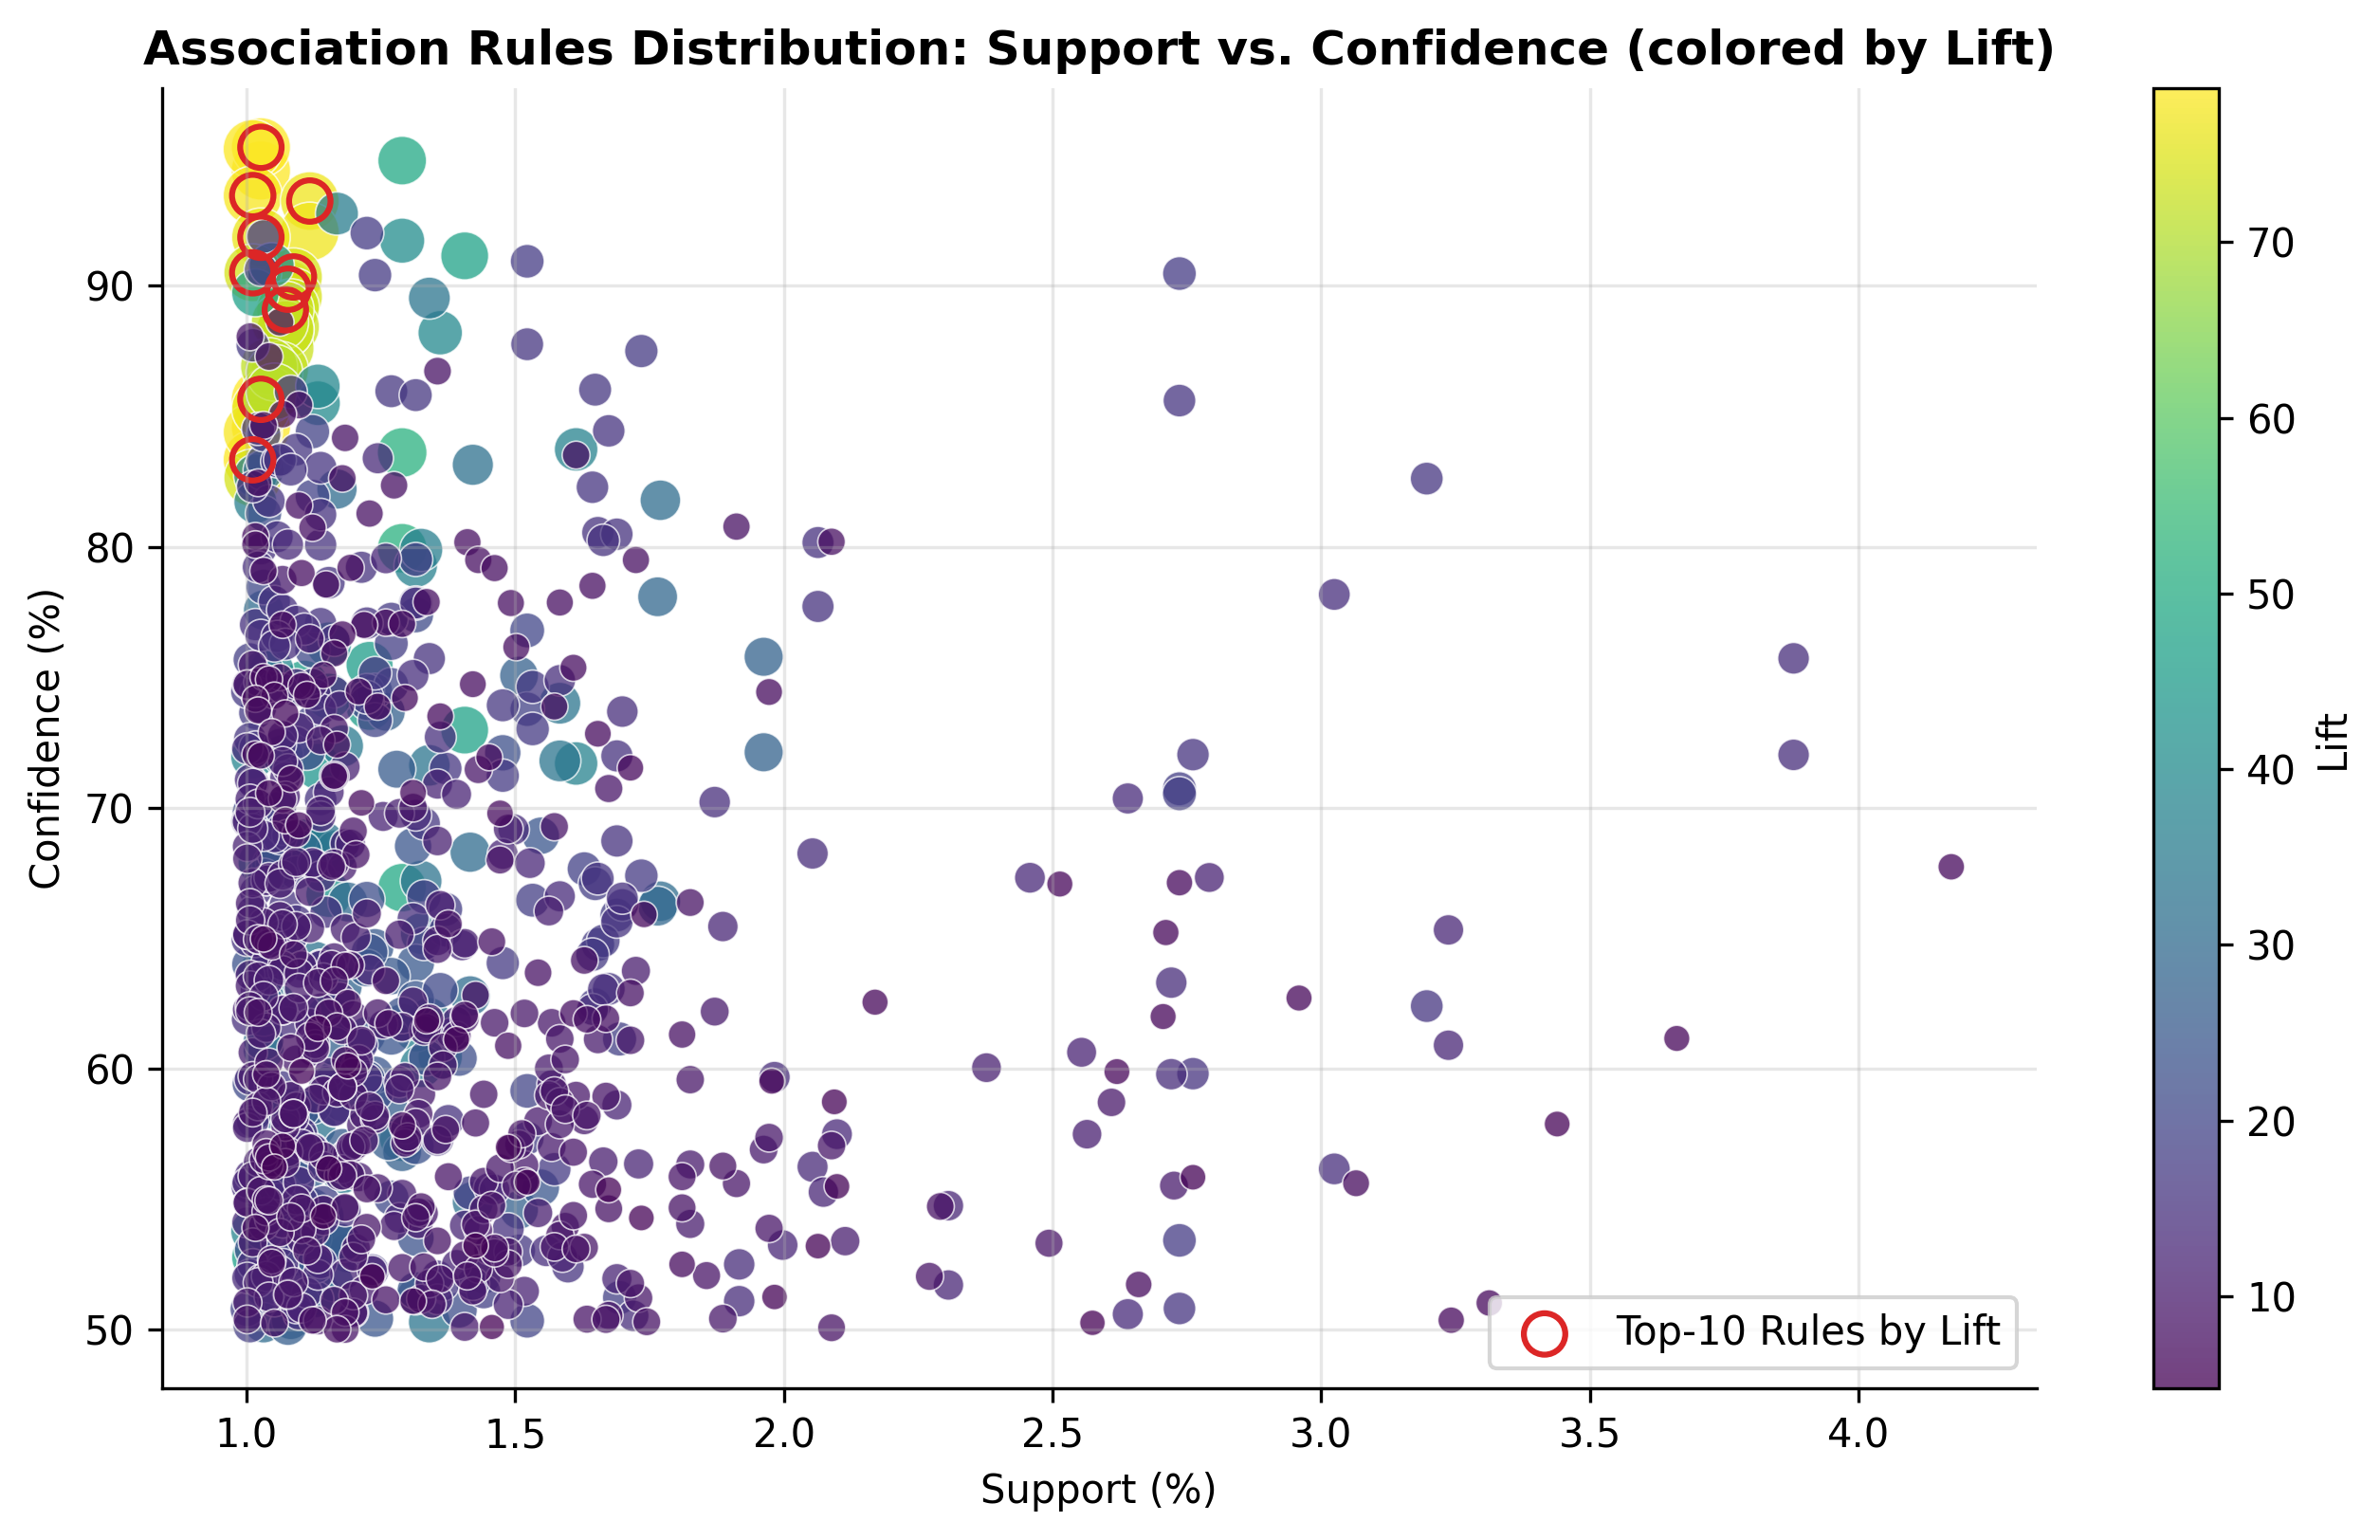

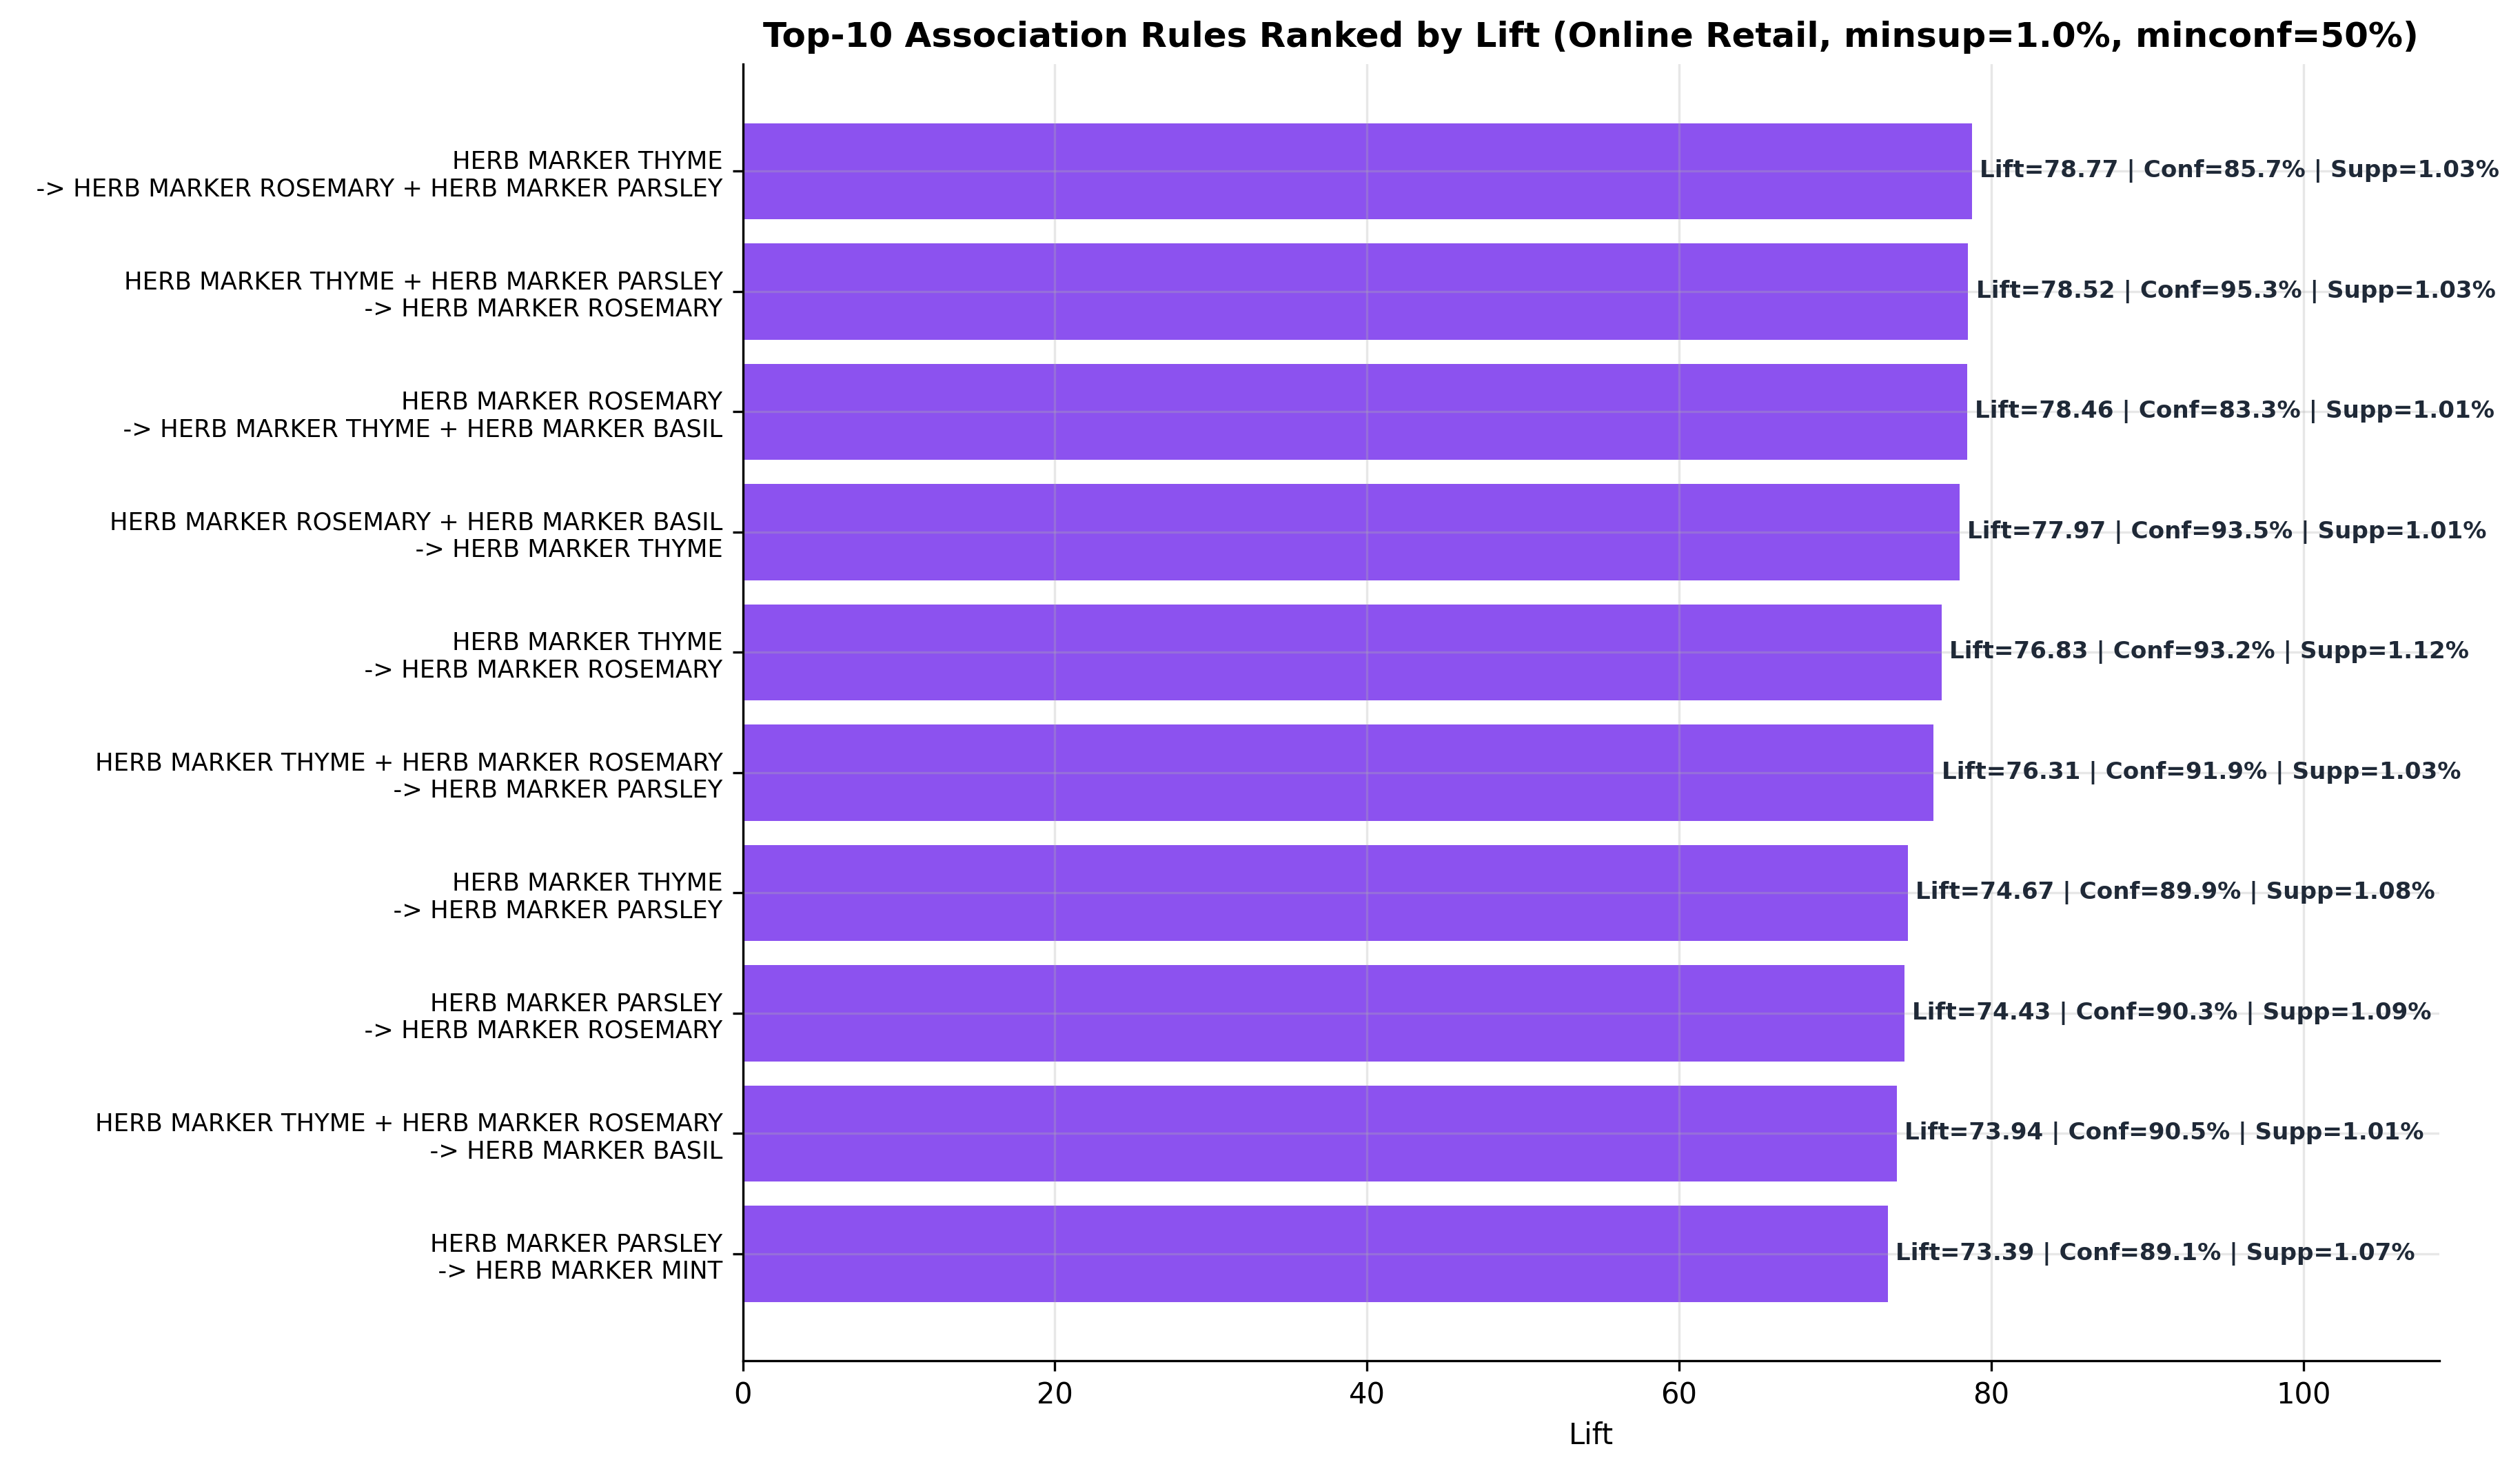

In [5]:
from IPython.display import Image, display as ipy_display

subprocess.run(["python", "applications/market_basket/plot_mba.py"], check=True)

for fig_name in [
    "fig1_top15_products.png",
    "fig2_minsup_sensitivity.png",
    "fig3_rules_scatter.png",
    "fig4_top10_lift.png",
]:
    ipy_display(Image(filename=f"results/app1/figures/{fig_name}"))

## 6. Diễn giải ý nghĩa kinh doanh & Khuyến nghị thực tiễn

Từ **962 luật kết hợp** khai thác được bằng **Optimized CHARM (`CharmMining.jl`)** tại `minsup = 1.0%`, `minconf = 50%`, nhóm rút ra 4 phát hiện cốt lõi và khuyến nghị hành động:

1. **Đóng gói Combo trọn bộ sưu tập (Collection Bundling):** Toàn bộ Top-10 luật theo Lift (`73.39 – 78.77`, Confidence `83.3% – 95.3%`) thuộc bộ nhãn cắm thảo mộc **Herb Marker** (`THYME`, `ROSEMARY`, `PARSLEY`, `BASIL`, `MINT`), cùng các bộ sưu tập đồng bộ khác như **Regency Tea Plate** (`Lift = 51.82`) và nhà búp bê **Poppy's Playhouse** (`Lift = 43.14`). Khuyến nghị tạo SKU combo trọn bộ giảm 8–10% và nút *"Thêm trọn bộ 1 cú nhấp"* ngay trên trang chi tiết sản phẩm.
2. **Bán chéo sản phẩm bổ trợ chức năng (True Complementary Cross-Selling):** Các cặp bổ trợ thực sự như `REGENCY SUGAR BOWL GREEN => REGENCY MILK JUG PINK` (`Confidence = 75.5%`, `Lift = 45.36`) và `GARAGE KEY FOB => KEY FOB , SHED` (`Confidence = 71.9%`, `Lift = 38.24`) nên được tích hợp vào widget *"Frequently Bought Together"* tại giỏ hàng và bố trí kệ/danh mục theo ngữ cảnh sử dụng (*Tiệc trà chiều*, *Nhà & Vườn*).
3. **Chiến dịch theo mùa vụ (Seasonal Merchandising):** Các phụ kiện trang trí gỗ Giáng sinh (`WOODEN TREE` / `SLEIGH` $\Rightarrow$ `WOODEN STOCKING`, `Lift = 42.08 – 46.33`) phù hợp triển khai ưu đãi *"Mua 2 tặng 1 / Giảm 15% món thứ 3"* giai đoạn tháng 10–12 để tăng AOV.
4. **Chính sách chiết khấu cặp mẫu cho khách sỉ B2B & hộ gia đình:** Luật `CHILDRENS CUTLERY DOLLY GIRL => CHILDRENS CUTLERY SPACEBOY` (`Confidence = 76.2%`, `Lift = 40.97`) phản ánh nhu cầu mua đồng bộ 2 phiên bản của các gia đình nhiều con và cửa hàng quà tặng nhập sỉ B2B — khuyến nghị áp dụng gói *Assorted Pack Discount* và dự báo tồn kho đồng bộ.

Xem phân tích chi tiết đầy đủ tại [`docs/app1_market_basket.md`](../docs/app1_market_basket.md).